# Route Ranker  --  AI-Powered Public Transit Route Optimization

In [4]:
import pandas as pd
from pathlib import Path
import numpy as np

import matplotlib.pyplot as plt
import seaborn as sns

In [5]:
DATA_DIR = Path.cwd()

print("Current directory:", DATA_DIR)
print("\nAvailable CSV files:")

for file in sorted(DATA_DIR.glob("*.csv")):
    print(f"{file.name}: {file.stat().st_size / (1024**2):.2f} MB")


Current directory: /mnt/windows/uhh/ideas/AI

Available CSV files:
calendar.csv: 0.00 MB
calendar_cleaned.csv: 0.00 MB
dataset_inventory.csv: 0.00 MB
hourly_route_frequency.csv: 0.53 MB
route_optimization_comparison.csv: 0.00 MB
route_optimization_recommendations.csv: 0.03 MB
route_trip_frequency.csv: 0.04 MB
routes.csv: 0.18 MB
stop_times.csv: 231.44 MB
stops.csv: 1.11 MB
trips.csv: 9.54 MB


## Relation between every files

In [6]:

files = [
    "routes.csv",
    "trips.csv",
    "stops.csv",
    "calendar.csv",
    "dataset_inventory.csv"
]

for filename in files:
    path = DATA_DIR / filename

    if path.exists():
        df = pd.read_csv(path, nrows=5)

        print(f"\n--- {filename} ---")
        print("Columns:", df.columns.tolist())
        display(df.head(3))
    else:
        print(f"Missing: {filename}")



--- routes.csv ---
Columns: ['city', 'route_id', 'agency_id', 'route_short_name', 'route_long_name', 'route_type']


,city,route_id,agency_id,route_short_name,route_long_name,route_type
0,amhedabad,101sh,AMTS,101sh,P.D.P.U. Cross Road ⇆ Asarva Railway Station,3
1,amhedabad,103-1,AMTS,103,Bhakti Circle ⇆ Gujarat University,3
2,amhedabad,103-2,AMTS,103,Bhakti Circle ⇆ Sarangpur,3



--- trips.csv ---
Columns: ['city', 'route_id', 'service_id', 'trip_id', 'trip_headsign', 'direction_id', 'shape_id']


,city,route_id,service_id,trip_id,trip_headsign,direction_id,shape_id
0,amhedabad,101sh,"1,2,3,4,5,6,7",AMC_9348910,Asarva Railway Station,1,NaN
1,amhedabad,101sh,"1,2,3,4,5,6,7",AMC_9348912,Asarva Railway Station,1,NaN
2,amhedabad,101sh,"1,2,3,4,5,6,7",AMC_9348914,Asarva Railway Station,1,NaN



--- stops.csv ---
Columns: ['city', 'stop_id', 'stop_name', 'stop_lat', 'stop_lon']


,city,stop_id,stop_name,stop_lat,stop_lon
0,amhedabad,AMC_6161,P.D.P.U. Cross Road,23.15995,72.63550
1,amhedabad,AMC_6163,Gandhinagar Kelvani Mandal,23.15614,72.63511
2,amhedabad,AMC_2314,Preksha Bharati,23.15087,72.63487



--- calendar.csv ---
Columns: ['city', 'service_id', 'monday', 'tuesday', 'wednesday', 'thursday', 'friday', 'saturday', 'sunday', 'start_date', 'end_date']


,city,service_id,monday,tuesday,wednesday,thursday,friday,saturday,sunday,start_date,end_date
0,amhedabad,"1,2,3,4,5,6,7",1,1,1,1,1,1,1,20260930,20270329
1,dharwad,"1,2,3,4,5,6,7",1,1,1,1,1,1,1,20260824,20270220
2,dharwad,"1,2,3,4,5,6,0",1,1,1,1,1,1,0,20260824,20270220



--- dataset_inventory.csv ---
Columns: ['city', 'file', 'status', 'records']


,city,file,status,records
0,amhedabad,routes.txt,LOADED,639
1,amhedabad,trips.txt,LOADED,14323
2,amhedabad,stop_times.txt,LOADED,646471


In [7]:
stop_times_path = DATA_DIR / "stop_times.csv"

for chunk in pd.read_csv(stop_times_path, chunksize=100_000):
    print("First chunk rows:", len(chunk))
    print("Columns:", chunk.columns.tolist())
    display(chunk.head(3))
    break


First chunk rows: 100000
Columns: ['city', 'trip_id', 'arrival_time', 'departure_time', 'stop_id', 'stop_sequence', 'timepoint']


,city,trip_id,arrival_time,departure_time,stop_id,stop_sequence,timepoint
0,amhedabad,AMC_9335652,05:15:00,05:15:00,AMC_317,1,1
1,amhedabad,AMC_9335652,05:17:00,05:17:00,AMC_2239,2,0
2,amhedabad,AMC_9335652,05:18:00,05:18:00,AMC_2714,3,0


In [8]:
DATA_DIR = Path.cwd()

files = [
    "routes.csv",
    "trips.csv",
    "stop_times.csv",
    "stops.csv",
    "calendar.csv",
    "dataset_inventory.csv"
]

results = []

for filename in files:
    path = DATA_DIR / filename

    if not path.exists():
        results.append({
            "File": filename,
            "Records": "FILE NOT FOUND"
        })
        continue

    total_records = 0

    for chunk in pd.read_csv(
        path,
        chunksize=100_000,
        usecols=[0]
    ):
        total_records += len(chunk)

    results.append({
        "File": filename,
        "Records": total_records
    })

result_df = pd.DataFrame(results)
display(result_df)


,File,Records
0,routes.csv,2780
1,trips.csv,141547
2,stop_times.csv,4247945
3,stops.csv,20751
4,calendar.csv,8
5,dataset_inventory.csv,35


## Data Cleaning

In [9]:
routes = pd.read_csv("routes.csv")
routes.head()
# routes.isnull().sum()

,city,route_id,agency_id,route_short_name,route_long_name,route_type
0,amhedabad,101sh,AMTS,101sh,P.D.P.U. Cross Road ⇆ Asarva Railway Station,3
1,amhedabad,103-1,AMTS,103,Bhakti Circle ⇆ Gujarat University,3
2,amhedabad,103-2,AMTS,103,Bhakti Circle ⇆ Sarangpur,3
3,amhedabad,103-3,AMTS,103,Gujarat University ⇆ Sarangpur,3
4,amhedabad,105,AMTS,105,Naroda Industrial Township( MuthiyaGam ) ⇆ Lal...,3


In [10]:
stop_times = pd.read_csv(
    "stop_times.csv",
    dtype={
        "trip_id": "string",
        "arrival_time": "string",
        "departure_time": "string",
        "stop_id": "string",
    },
    low_memory=False
)

stop_times.head()
# stop_times.isnull().sum()

,city,trip_id,arrival_time,departure_time,stop_id,stop_sequence,timepoint
0,amhedabad,AMC_9335652,05:15:00,05:15:00,AMC_317,1,1.0
1,amhedabad,AMC_9335652,05:17:00,05:17:00,AMC_2239,2,0.0
2,amhedabad,AMC_9335652,05:18:00,05:18:00,AMC_2714,3,0.0
3,amhedabad,AMC_9335652,05:20:00,05:20:00,AMC_2713,4,0.0
4,amhedabad,AMC_9335652,05:22:00,05:22:00,AMC_2260,5,0.0


In [11]:
stops = pd.read_csv("stops.csv")
stops.head()
# stops.isnull().sum()

,city,stop_id,stop_name,stop_lat,stop_lon
0,amhedabad,AMC_6161,P.D.P.U. Cross Road,23.15995,72.63550
1,amhedabad,AMC_6163,Gandhinagar Kelvani Mandal,23.15614,72.63511
2,amhedabad,AMC_2314,Preksha Bharati,23.15087,72.63487
3,amhedabad,AMC_2315,Kamalam,23.14757,72.63452
4,amhedabad,AMC_2316,Mahavir Hills,23.14594,72.63434


In [12]:
trips = pd.read_csv("trips.csv", low_memory=False)

# Keep identifiers and text as strings
string_cols = [
    "city",
    "route_id",
    "service_id",
    "trip_id",
    "trip_headsign",
    "shape_id"
]

for col in string_cols:
    trips[col] = trips[col].astype("string")

# Keep direction_id numeric
trips["direction_id"] = pd.to_numeric(
    trips["direction_id"], errors="coerce"
).astype("Int64")

# print(trips.dtypes)
trips.head()


,city,route_id,service_id,trip_id,trip_headsign,direction_id,shape_id
0,amhedabad,101sh,"1,2,3,4,5,6,7",AMC_9348910,Asarva Railway Station,1,<NA>
1,amhedabad,101sh,"1,2,3,4,5,6,7",AMC_9348912,Asarva Railway Station,1,<NA>
2,amhedabad,101sh,"1,2,3,4,5,6,7",AMC_9348914,Asarva Railway Station,1,<NA>
3,amhedabad,101sh,"1,2,3,4,5,6,7",AMC_9348916,Asarva Railway Station,1,<NA>
4,amhedabad,101sh,"1,2,3,4,5,6,7",AMC_9348918,Asarva Railway Station,1,<NA>


In [13]:
# Remove extra spaces and standardize missing values

datasets = [routes, stop_times, stops, trips]

for df in datasets:
    df.columns = df.columns.str.strip()

    for col in df.select_dtypes(include="object").columns:
        df[col] = df[col].str.strip()

    df.replace(
        ["", "NA", "N/A", "NULL", "null", "None"],
        np.nan,
        inplace=True
    )

/tmp/ipykernel_5602/3164282683.py:8: Pandas4Warning: For backward compatibility, 'str' dtypes are included by select_dtypes when 'object' dtype is specified. This behavior is deprecated and will be removed in a future version. Explicitly pass 'str' to `include` to select them, or to `exclude` to remove them and silence this warning.
See https://pandas.pydata.org/docs/dev/user_guide/migration.html#string-migration-select-dtypes for details on how to write code that works with pandas 2 and 3.
  for col in df.select_dtypes(include="object").columns:
/tmp/ipykernel_5602/3164282683.py:8: Pandas4Warning: For backward compatibility, 'str' dtypes are included by select_dtypes when 'object' dtype is specified. This behavior is deprecated and will be removed in a future version. Explicitly pass 'str' to `include` to select them, or to `exclude` to remove them and silence this warning.
See https://pandas.pydata.org/docs/dev/user_guide/migration.html#string-migration-select-dtypes for details on h

In [14]:
# missing values

print("ROUTES")
print(routes.isnull().sum())

print("\nSTOP TIMES")
print(stop_times.isnull().sum())

print("\nSTOPS")
print(stops.isnull().sum())

print("\nTRIPS")
print(trips.isnull().sum())

ROUTES
city                0
route_id            0
agency_id           0
route_short_name    0
route_long_name     0
route_type          0
dtype: int64

STOP TIMES
city                  0
trip_id               0
arrival_time          0
departure_time        0
stop_id               0
stop_sequence         0
timepoint         17783
dtype: int64

STOPS
city         0
stop_id      0
stop_name    0
stop_lat     0
stop_lon     0
dtype: int64

TRIPS
city                  0
route_id              0
service_id            0
trip_id               0
trip_headsign       586
direction_id       1047
shape_id         126311
dtype: int64


In [15]:
# Remove Duplicate rows
routes = routes.drop_duplicates()
stop_times = stop_times.drop_duplicates()
stops = stops.drop_duplicates()
trips = trips.drop_duplicates()

In [16]:
# Check missing essential identifiers

print("ROUTES")
print(routes[["city", "route_id"]].isnull().sum())

print("\nTRIPS")
print(trips[["city", "route_id", "trip_id", "service_id"]].isnull().sum())

print("\nSTOP TIMES")
print(stop_times[
    ["city", "trip_id", "stop_id", "stop_sequence", "departure_time"]
].isnull().sum())

print("\nSTOPS")
print(stops[["city", "stop_id", "stop_lat", "stop_lon"]].isnull().sum())

ROUTES
city        0
route_id    0
dtype: int64

TRIPS
city          0
route_id      0
trip_id       0
service_id    0
dtype: int64

STOP TIMES
city              0
trip_id           0
stop_id           0
stop_sequence     0
departure_time    0
dtype: int64

STOPS
city        0
stop_id     0
stop_lat    0
stop_lon    0
dtype: int64


In [17]:
print("route_type:")
print(routes["route_type"].dropna().unique()[:20])

print("\ntimepoint:")
print(stop_times["timepoint"].dropna().unique()[:20])

print("\ndirection_id:")
print(trips["direction_id"].dropna().unique()[:20])


route_type:
[3]

timepoint:
[1.00000000e+00 0.00000000e+00 7.67501009e+02 1.91599585e+03
 2.52578184e+03 3.44232500e+03 4.18691418e+03 4.72477551e+03
 5.02824748e+03 5.67560024e+03 6.67179025e+03 9.43920962e+03
 1.12867525e+04 1.30400657e+04 1.09055454e+03 1.56984398e+03
 2.88406794e+03 1.11371825e+03 3.85551642e+03 5.44526715e+03]

direction_id:
<IntegerArray>
[1, 0]
Length: 2, dtype: Int64


In [18]:
# Route type: numeric, nullable integer
routes["route_type"] = pd.to_numeric(
    routes["route_type"], errors="coerce"
).astype("Int64")

# Stop sequence: numeric, allowing missing values
stop_times["stop_sequence"] = pd.to_numeric(
    stop_times["stop_sequence"], errors="coerce"
)

# Stop coordinates: numeric
stops["stop_lat"] = pd.to_numeric(
    stops["stop_lat"], errors="coerce"
)

stops["stop_lon"] = pd.to_numeric(
    stops["stop_lon"], errors="coerce"
)

# Timepoint: preserve missing values
stop_times["timepoint"] = pd.to_numeric(
    stop_times["timepoint"], errors="coerce"
)

# Direction ID: preserve missing values
trips["direction_id"] = pd.to_numeric(
    trips["direction_id"], errors="coerce"
).astype("Int64")

print("Data type conversion completed.")
print("Timepoint dtype:", stop_times["timepoint"].dtype)
print("Direction ID dtype:", trips["direction_id"].dtype)


Data type conversion completed.
Timepoint dtype: float64
Direction ID dtype: Int64


In [19]:
# Create Time based feature
# Extract hour from departure_time
stop_times["hour_of_day"] = pd.to_numeric(
    stop_times["departure_time"].str.split(":").str[0],
    errors="coerce"
)

# Display the result
print(stop_times[
    ["departure_time", "hour_of_day"]
].head(10))


  departure_time  hour_of_day
0       05:15:00            5
1       05:17:00            5
2       05:18:00            5
3       05:20:00            5
4       05:22:00            5
5       05:22:00            5
6       05:23:00            5
7       05:24:00            5
8       05:25:00            5
9       05:26:00            5


In [20]:
# Calendar data
calendar = pd.read_csv("calendar_cleaned.csv")

print(calendar.shape)
print(calendar.columns.tolist())
print(calendar.head())


(8, 13)
['city', 'service_id', 'monday', 'tuesday', 'wednesday', 'thursday', 'friday', 'saturday', 'sunday', 'start_date', 'end_date', 'weekday_service', 'weekend_service']
        city     service_id  monday  tuesday  wednesday  thursday  friday  \
0  amhedabad  1,2,3,4,5,6,7       1        1          1         1       1   
1    dharwad  1,2,3,4,5,6,7       1        1          1         1       1   
2    dharwad  1,2,3,4,5,6,0       1        1          1         1       1   
3  karnataka        WEEKDAY       1        1          1         1       1   
4     mumbai  1,2,3,4,5,6,7       1        1          1         1       1   

   saturday  sunday  start_date    end_date  weekday_service  weekend_service  
0         1       1  2026-09-30  2027-03-29                1                1  
1         1       1  2026-08-24  2027-02-20                1                1  
2         1       0  2026-08-24  2027-02-20                1                1  
3         1       1  2026-06-02  2026-11-29 

In [21]:
# Step 1: Calculate trip frequency per route

trip_frequency = (
    trips.groupby(["city", "route_id"])["trip_id"]
    .nunique()
    .reset_index(name="trip_frequency")
)

print(trip_frequency.head(10))
print("Total route profiles:", len(trip_frequency))


        city  route_id  trip_frequency
0  amhedabad     101-C              96
1  amhedabad  101-C-PR               4
2  amhedabad  101-C-RS               3
3  amhedabad   101S-RM               6
4  amhedabad   101U-NR               6
5  amhedabad     101sh              10
6  amhedabad     102-1               6
7  amhedabad     102-2               2
8  amhedabad     102-3               8
9  amhedabad     103-1              22
Total route profiles: 2370


In [22]:
# Step 2: Validate weekday and weekend service

print("Weekday service values:")
print(calendar["weekday_service"].value_counts(dropna=False))

print("\nWeekend service values:")
print(calendar["weekend_service"].value_counts(dropna=False))

print("\nMissing service values:")
print(calendar[["weekday_service", "weekend_service"]].isnull().sum())


Weekday service values:
weekday_service
1    8
Name: count, dtype: int64

Weekend service values:
weekend_service
1    8
Name: count, dtype: int64

Missing service values:
weekday_service    0
weekend_service    0
dtype: int64


In [23]:
# Save route trip frequency
trip_frequency.to_csv("route_trip_frequency.csv", index=False)

print("Route trip frequency saved successfully!")
print(trip_frequency.head())

Route trip frequency saved successfully!
        city  route_id  trip_frequency
0  amhedabad     101-C              96
1  amhedabad  101-C-PR               4
2  amhedabad  101-C-RS               3
3  amhedabad   101S-RM               6
4  amhedabad   101U-NR               6


In [24]:
# Count scheduled trips per route per hour

hourly_trips = stop_times.merge(
    trips[["city", "trip_id", "route_id"]],
    on=["city", "trip_id"],
    how="inner"
)

hourly_route_frequency = (
    hourly_trips.groupby(
        ["city", "route_id", "hour_of_day"]
    )["trip_id"]
    .nunique()
    .reset_index(name="scheduled_trips")
)

print(hourly_route_frequency.head(10))

hourly_route_frequency.to_csv(
    "hourly_route_frequency.csv",
    index=False
)

        city route_id  hour_of_day  scheduled_trips
0  amhedabad    101-C            6                7
1  amhedabad    101-C            7               17
2  amhedabad    101-C            8               23
3  amhedabad    101-C            9               22
4  amhedabad    101-C           10               19
5  amhedabad    101-C           11               17
6  amhedabad    101-C           12               14
7  amhedabad    101-C           13               11
8  amhedabad    101-C           14               10
9  amhedabad    101-C           15               10


## EDA

city
mumbai       935
amhedabad    639
dharwad      632
pune         309
rajkot       150
karnataka     93
vapi          22
Name: route_id, dtype: int64


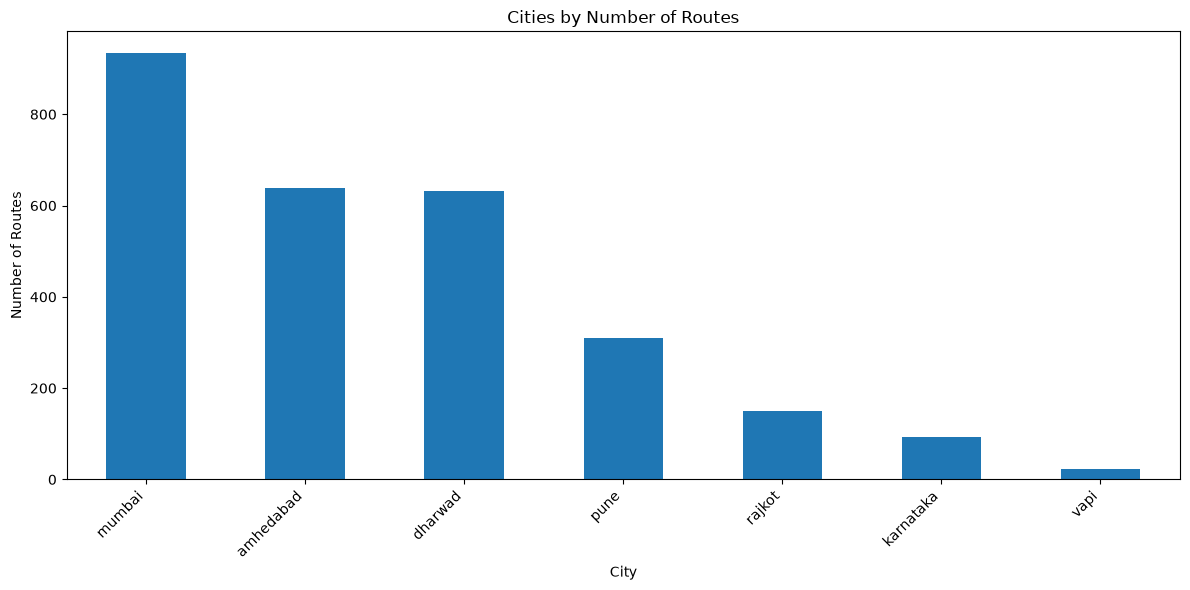

In [25]:
# Count routes in each city
city_routes = routes.groupby("city")["route_id"].nunique()

# Sort cities by route count
city_routes = city_routes.sort_values(ascending=False)

# Display the top  cities
print(city_routes.head(10))

# Visualize
plt.figure(figsize=(12, 6))

city_routes.head(10).plot(kind="bar")

plt.title("Cities by Number of Routes")
plt.xlabel("City")
plt.ylabel("Number of Routes")
plt.xticks(rotation=45, ha="right")
plt.tight_layout()
plt.show()

Route type distribution:
route_type
3    2780
Name: count, dtype: Int64


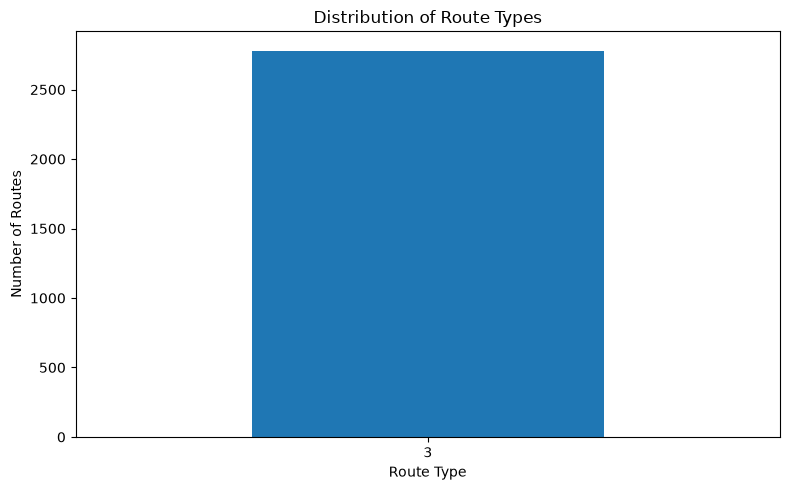

In [26]:
# Count routes by transport type
route_type_counts = routes["route_type"].value_counts().sort_index()

print("Route type distribution:")
print(route_type_counts)

# Create bar chart
plt.figure(figsize=(8, 5))

route_type_counts.plot(kind="bar")

plt.title("Distribution of Route Types")
plt.xlabel("Route Type")
plt.ylabel("Number of Routes")
plt.xticks(rotation=0)
plt.tight_layout()
plt.show()

In [27]:
# Count distinct scheduled trips for each route
route_trip_counts = (
    trips.groupby(["city", "route_id"])["trip_id"]
    .nunique()
    .reset_index(name="scheduled_trip_count")
)

# Display the 10 routes with the most scheduled trips
top_routes = route_trip_counts.sort_values(
    "scheduled_trip_count", ascending=False
).head(10)

display(top_routes)

,city,route_id,scheduled_trip_count
1313,mumbai,117RING,930
1311,mumbai,116AS,911
1378,mumbai,182RING,904
1627,mumbai,401AS,830
1517,mumbai,310-1,827
1477,mumbai,273AS-2,812
1413,mumbai,217-1,789
1572,mumbai,350AS,774
1826,mumbai,809AS,752
1781,mumbai,63AS-1,745


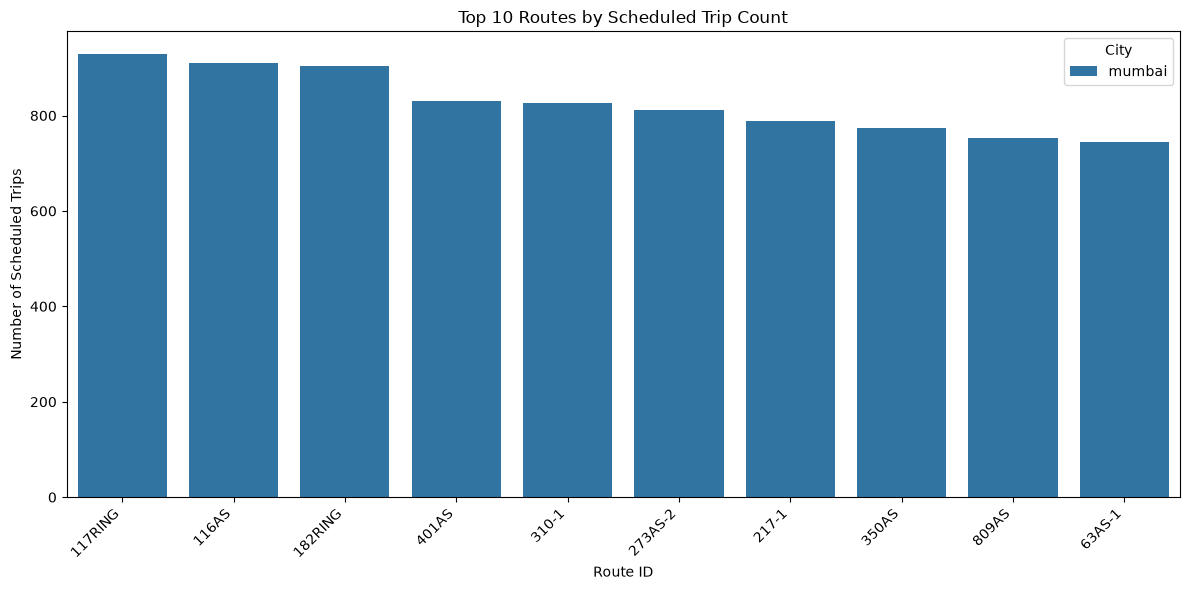

In [28]:
plt.figure(figsize=(12, 6))

sns.barplot(
    data=top_routes,
    x="route_id",
    y="scheduled_trip_count",
    hue="city",
    dodge=False
)

plt.title("Top 10 Routes by Scheduled Trip Count")
plt.xlabel("Route ID")
plt.ylabel("Number of Scheduled Trips")
plt.xticks(rotation=45, ha="right")
plt.legend(title="City")
plt.tight_layout()
plt.show()

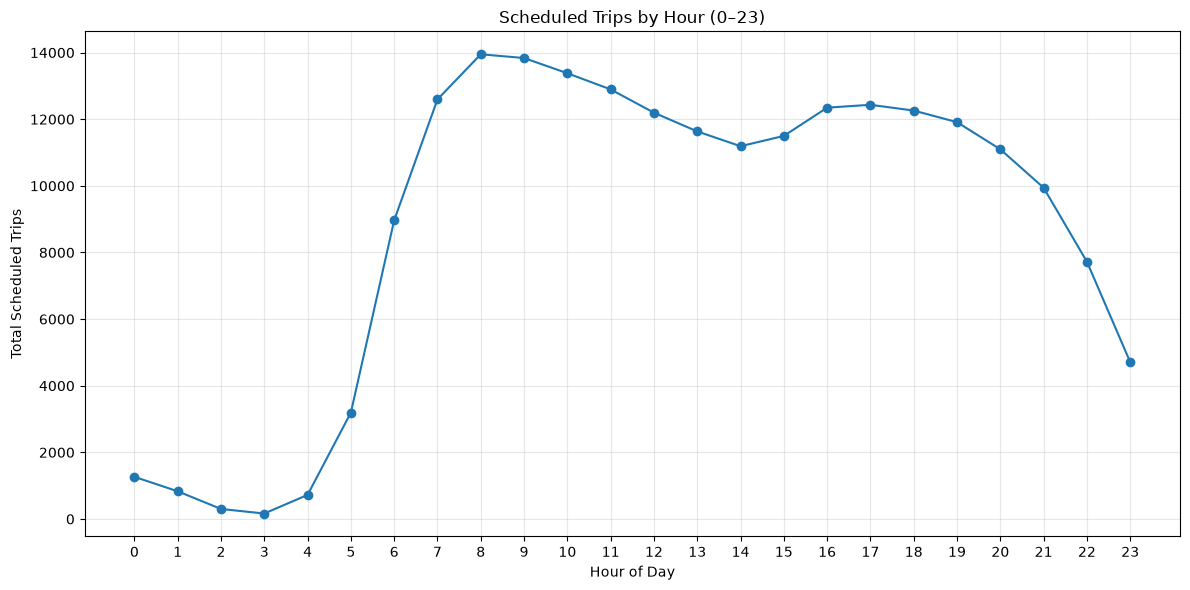

Peak hour: 8
Peak scheduled trips: 13949


In [29]:
# Total scheduled trips for each hour across all cities and routes
hourly_df = pd.read_csv("hourly_route_frequency.csv")

normal_hours = hourly_df[
    hourly_df["hour_of_day"].between(0, 23)
]

hourly_summary_24 = (
    normal_hours.groupby("hour_of_day")["scheduled_trips"]
    .sum()
    .reindex(range(24), fill_value=0)
)

plt.figure(figsize=(12, 6))

plt.plot(
    hourly_summary_24.index,
    hourly_summary_24.values,
    marker="o"
)

plt.title("Scheduled Trips by Hour (0–23)")
plt.xlabel("Hour of Day")
plt.ylabel("Total Scheduled Trips")
plt.xticks(range(24))
plt.grid(True, alpha=0.3)
plt.tight_layout()
plt.show()

print("Peak hour:", hourly_summary_24.idxmax())
print("Peak scheduled trips:", hourly_summary_24.max())

Scheduled trips by time period:
time_period
Night         3286
Morning      78819
Afternoon    58866
Evening      70079
Name: scheduled_trips, dtype: int64


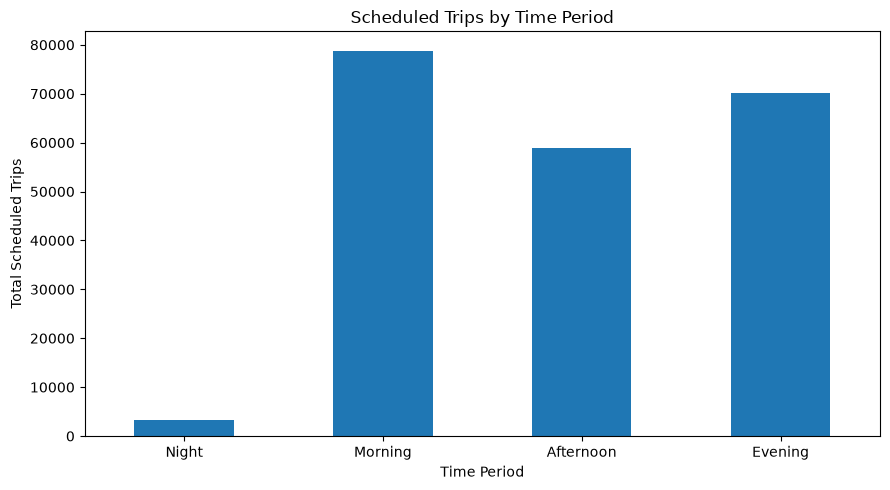

In [30]:
# Use only the standard 24-hour window
period_df = hourly_df[
    hourly_df["hour_of_day"].between(0, 23)
].copy()

# Define time periods
def get_period(hour):
    if 0 <= hour <= 4:
        return "Night"
    elif 5 <= hour <= 11:
        return "Morning"
    elif 12 <= hour <= 16:
        return "Afternoon"
    else:
        return "Evening"

period_df["time_period"] = period_df["hour_of_day"].apply(get_period)

# Calculate scheduled trips for each period
period_summary = (
    period_df.groupby("time_period")["scheduled_trips"]
    .sum()
    .reindex(["Night", "Morning", "Afternoon", "Evening"])
)

print("Scheduled trips by time period:")
print(period_summary)

# Visualize
plt.figure(figsize=(9, 5))
period_summary.plot(kind="bar")

plt.title("Scheduled Trips by Time Period")
plt.xlabel("Time Period")
plt.ylabel("Total Scheduled Trips")
plt.xticks(rotation=0)
plt.tight_layout()
plt.show()

In [31]:
# Count unique stops in each city
city_stops = (
    stops.groupby("city")["stop_id"]
    .nunique()
    .sort_values(ascending=False)
)

# Display the top cities
print("Cities by number of stops:")
print(city_stops.head(10))

Cities by number of stops:
city
mumbai       7506
pune         6713
amhedabad    3203
dharwad      2332
rajkot        760
karnataka     146
vapi           91
Name: stop_id, dtype: int64


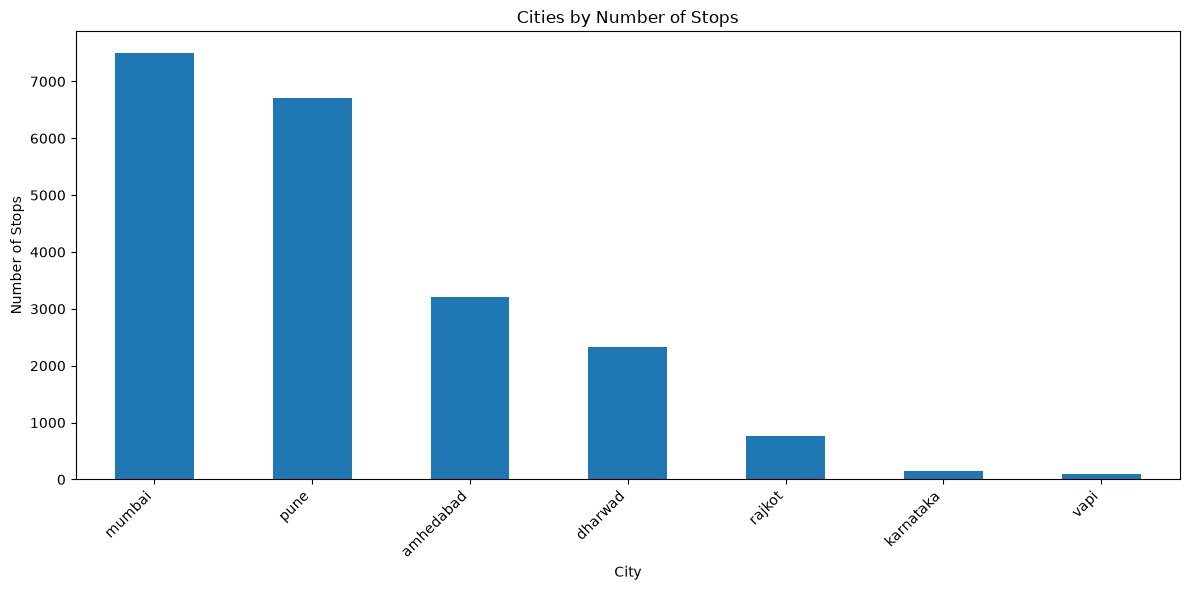

In [32]:
plt.figure(figsize=(12, 6))

city_stops.head(10).plot(kind="bar")

plt.title("Cities by Number of Stops")
plt.xlabel("City")
plt.ylabel("Number of Stops")
plt.xticks(rotation=45, ha="right")
plt.tight_layout()
plt.show()

In [33]:
# Count unique trips in each city
city_trips = (
    trips.groupby("city")["trip_id"]
    .nunique()
    .sort_values(ascending=False)
)

# Display top 10 cities
print("Cities by number of trips:")
print(city_trips.head(10))

Cities by number of trips:
city
mumbai       99080
pune         15236
amhedabad    14323
dharwad       8669
rajkot        3192
karnataka      586
vapi           461
Name: trip_id, dtype: int64


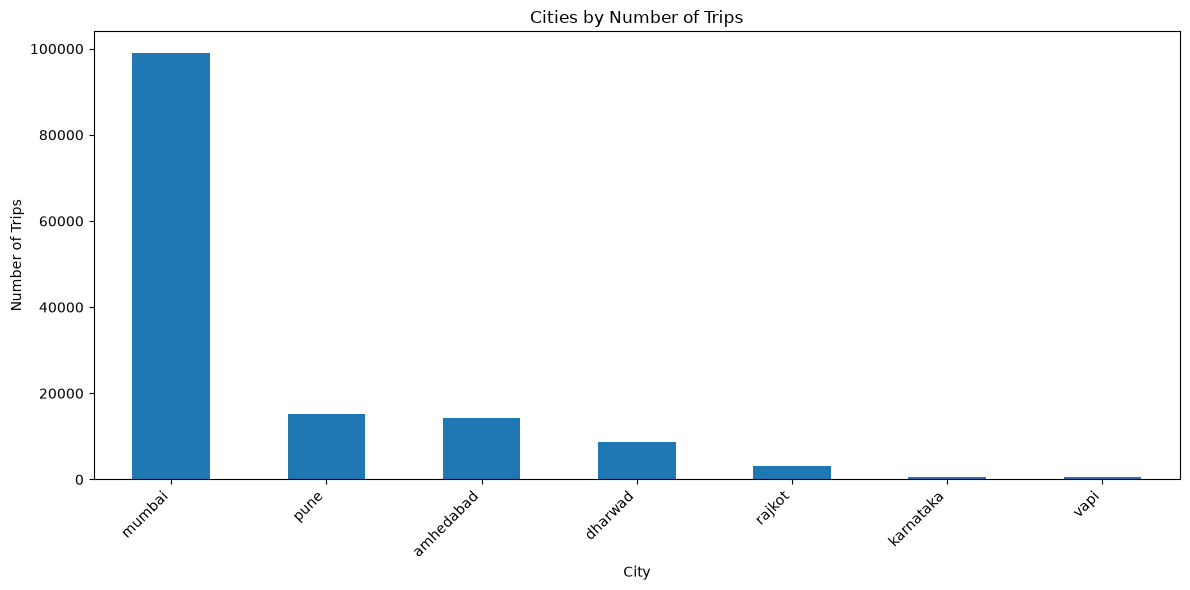

In [34]:
plt.figure(figsize=(12, 6))

city_trips.head(10).plot(kind="bar")

plt.title("Cities by Number of Trips")
plt.xlabel("City")
plt.ylabel("Number of Trips")
plt.xticks(rotation=45, ha="right")
plt.tight_layout()
plt.show()

In [35]:
# Count unique routes by city
city_routes = (
    df.groupby("city")["route_id"]
    .nunique()
    .rename("total_routes")
)

# Count unique trips by city
city_trips_count = (
    trips.groupby("city")["trip_id"]
    .nunique()
    .rename("total_trips")
)

# Combine both summaries
comparison = pd.concat(
    [city_routes, city_trips_count],
    axis=1
).fillna(0)

# Display top 10 cities by trip count
comparison = comparison.sort_values(
    "total_trips", ascending=False
).head(10)

display(comparison)

,total_routes,total_trips
city,,
mumbai,612,99080
pune,309,15236
amhedabad,633,14323
dharwad,630,8669
rajkot,150,3192
karnataka,14,586
vapi,22,461


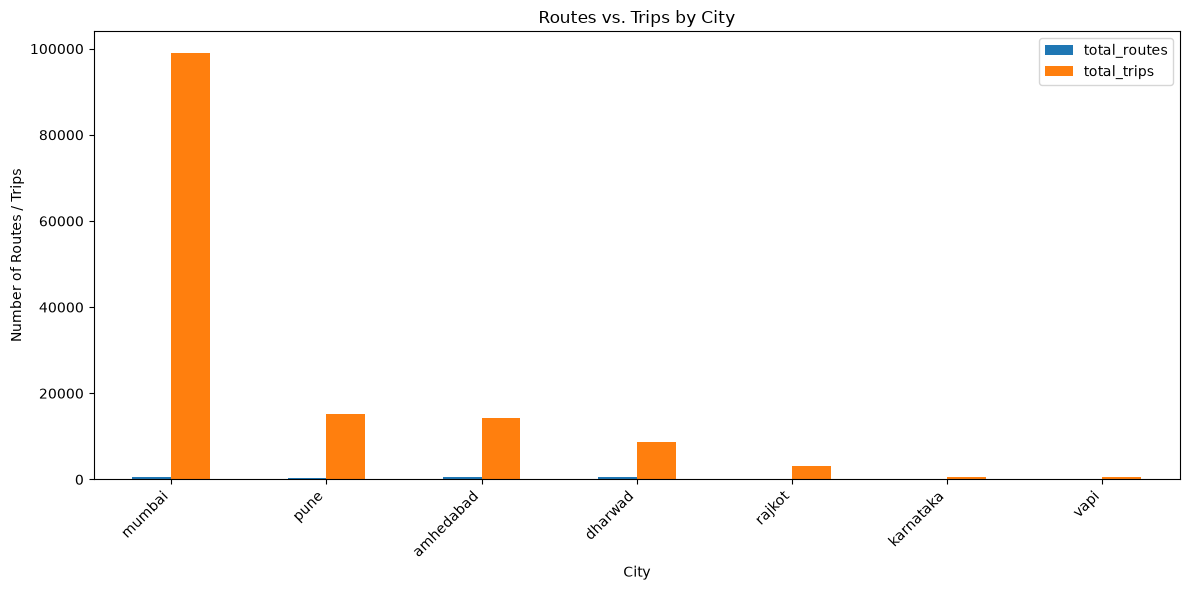

In [36]:
comparison.plot(
    kind="bar",
    figsize=(12, 6)
)

plt.title("Routes vs. Trips by City")
plt.xlabel("City")
plt.ylabel("Number of Routes / Trips")
plt.xticks(rotation=45, ha="right")
plt.tight_layout()
plt.show()

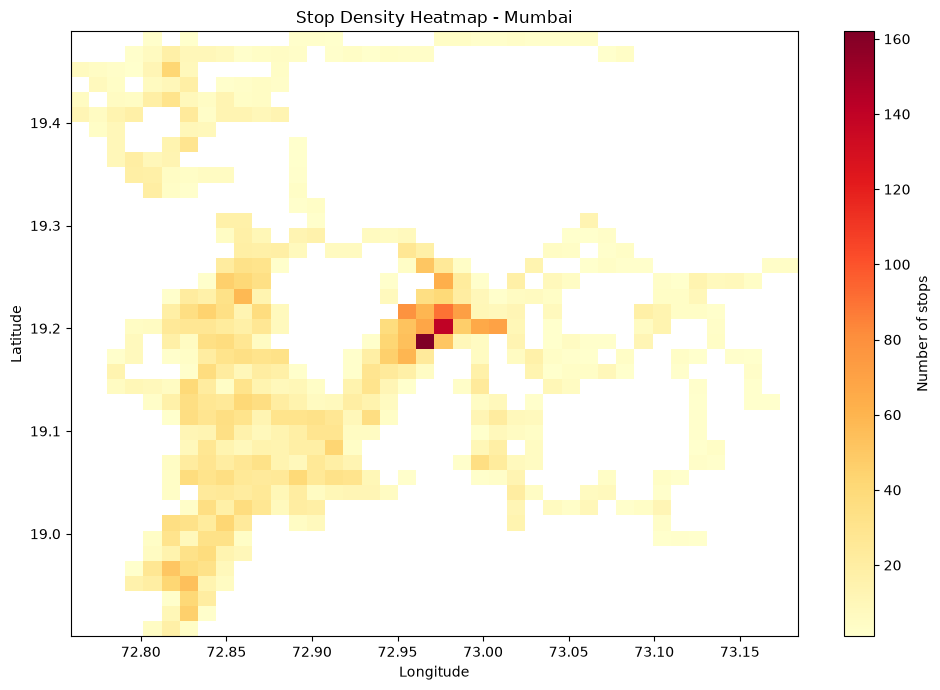

Selected city: mumbai
Stops plotted: 7506


In [37]:
# Load stops dataset
stops_df = pd.read_csv("stops.csv")

# Clean coordinate columns
stops_df["stop_lat"] = pd.to_numeric(
    stops_df["stop_lat"], errors="coerce"
)
stops_df["stop_lon"] = pd.to_numeric(
    stops_df["stop_lon"], errors="coerce"
)

# Remove rows with missing or invalid coordinates
stops_df = stops_df.dropna(
    subset=["city", "stop_lat", "stop_lon"]
)

# Select the city with the most recorded stops
selected_city = stops_df["city"].value_counts().idxmax()

city_stops = stops_df[
    stops_df["city"] == selected_city
]

# Plot density heatmap
plt.figure(figsize=(10, 7))

plt.hist2d(
    city_stops["stop_lon"],
    city_stops["stop_lat"],
    bins=40,
    cmap="YlOrRd",
    cmin=1
)

plt.colorbar(label="Number of stops")
plt.title(f"Stop Density Heatmap - {selected_city.title()}")
plt.xlabel("Longitude")
plt.ylabel("Latitude")
plt.tight_layout()
plt.show()

print("Selected city:", selected_city)
print("Stops plotted:", len(city_stops))


In [38]:
# Check Under utilize route
# Load hourly route data
hourly_df = pd.read_csv("hourly_route_frequency.csv")

# Calculate total scheduled trips for each route
route_usage = (
    hourly_df.groupby(["city", "route_id"])["scheduled_trips"]
    .sum()
    .reset_index()
)

# Sort routes by scheduled trips, from lowest to highest
route_usage = route_usage.sort_values(
    ["city", "scheduled_trips"],
    ascending=[True, True]
)

print("Routes with the lowest scheduled trip counts:")
display(route_usage.head(20))


Routes with the lowest scheduled trip counts:


,city,route_id,scheduled_trips
140,amhedabad,147/2-3,1
179,amhedabad,151/4-2,1
181,amhedabad,151/4-4,1
189,amhedabad,15E-AS,1
193,amhedabad,15S-PA,1
209,amhedabad,16S-JS,1
271,amhedabad,31/4sh-2,1
286,amhedabad,33/1sh-3,1
291,amhedabad,34/5-2,1
304,amhedabad,37sh-3,1


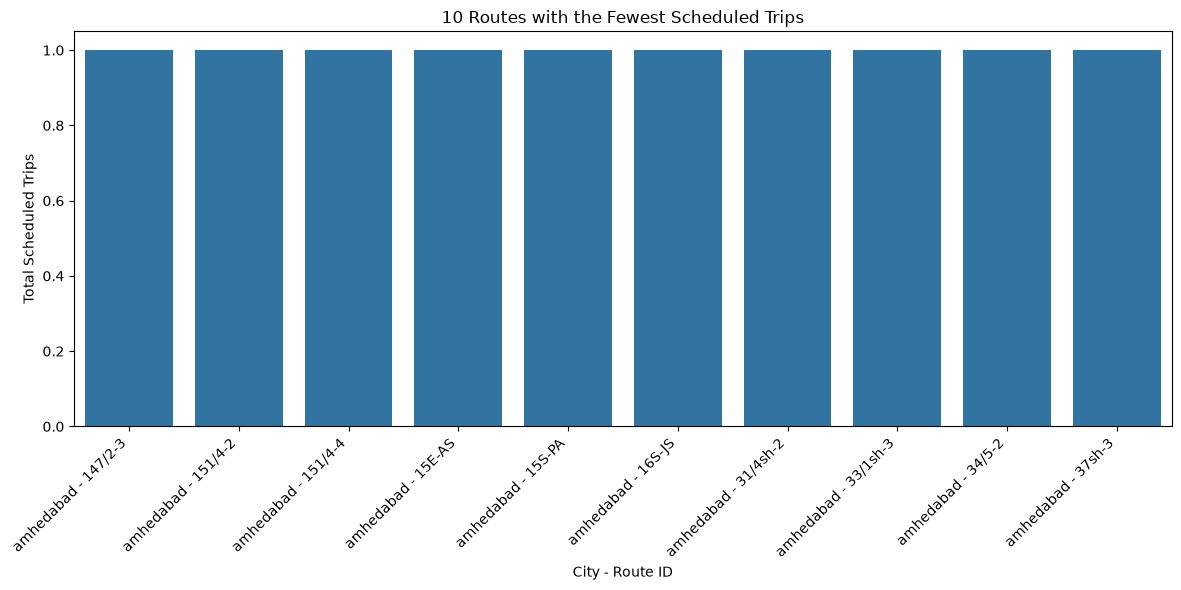

,city,route_id,scheduled_trips,route_label
140,amhedabad,147/2-3,1,amhedabad - 147/2-3
179,amhedabad,151/4-2,1,amhedabad - 151/4-2
181,amhedabad,151/4-4,1,amhedabad - 151/4-4
189,amhedabad,15E-AS,1,amhedabad - 15E-AS
193,amhedabad,15S-PA,1,amhedabad - 15S-PA
209,amhedabad,16S-JS,1,amhedabad - 16S-JS
271,amhedabad,31/4sh-2,1,amhedabad - 31/4sh-2
286,amhedabad,33/1sh-3,1,amhedabad - 33/1sh-3
291,amhedabad,34/5-2,1,amhedabad - 34/5-2
304,amhedabad,37sh-3,1,amhedabad - 37sh-3


In [39]:
# Select the 10 routes with the fewest scheduled trips
underused_routes = route_usage.nsmallest(10, "scheduled_trips").copy()

underused_routes["route_label"] = (
    underused_routes["city"] + " - " +
    underused_routes["route_id"].astype(str)
)

plt.figure(figsize=(12, 6))

sns.barplot(
    data=underused_routes,
    x="route_label",
    y="scheduled_trips"
)

plt.title("10 Routes with the Fewest Scheduled Trips")
plt.xlabel("City - Route ID")
plt.ylabel("Total Scheduled Trips")
plt.xticks(rotation=45, ha="right")
plt.tight_layout()
plt.show()

display(underused_routes)


In [40]:

# Check for routes with similar names in the same city

routes_df = pd.read_csv("routes.csv")

routes_df["route_short_name"] = (
    routes_df["route_short_name"]
    .fillna("")
    .astype(str)
    .str.strip()
)

routes_df["route_long_name"] = (
    routes_df["route_long_name"]
    .fillna("")
    .astype(str)
    .str.strip()
)

# Identify duplicate route names within each city
routes_df["duplicate_short_name"] = (
    routes_df.groupby(["city", "route_short_name"])["route_id"]
    .transform("count") > 1
)

routes_df["duplicate_long_name"] = (
    routes_df.groupby(["city", "route_long_name"])["route_id"]
    .transform("count") > 1
)

similar_routes = routes_df[
    (routes_df["duplicate_short_name"] & (routes_df["route_short_name"] != "")) |
    (routes_df["duplicate_long_name"] & (routes_df["route_long_name"] != ""))
]

print("Potential duplicate routes:", len(similar_routes))

display(
    similar_routes[
        ["city", "route_id", "route_short_name", "route_long_name"]
    ].head(20)
)


Potential duplicate routes: 1107


,city,route_id,route_short_name,route_long_name
1,amhedabad,103-1,103,Bhakti Circle ⇆ Gujarat University
2,amhedabad,103-2,103,Bhakti Circle ⇆ Sarangpur
3,amhedabad,103-3,103,Gujarat University ⇆ Sarangpur
5,amhedabad,107,107,Sarangpur ⇆ Sarangpur
6,amhedabad,109-1,109,Amba Township Sector-5 (Trimandir) ⇆ G.E.B (Na...
7,amhedabad,109-2,109,Amba Township Sector-5 (Trimandir) ⇆ Naroda
8,amhedabad,109-3,109,Chandkheda Gam ⇆ Amba Township Sector-5 (Trima...
9,amhedabad,109-4,109,Chandkheda Gam ⇆ Naroda
10,amhedabad,109-5,109,G.E.B (Naroda) ⇆ Chandkheda Gam
12,amhedabad,116-1,116,Dani Limda Gam ⇆ Civil Hospital


In [41]:

# Find stops shared by multiple routes

# Map each trip to its route
trip_routes = trips[
    ["city", "trip_id", "route_id"]
].drop_duplicates()

# Map each trip to the stops it visits
trip_stops = stop_times[
    ["city", "trip_id", "stop_id"]
].drop_duplicates()

# Connect trips, routes, and stops
route_stops = trip_stops.merge(
    trip_routes,
    on=["city", "trip_id"],
    how="inner"
)

# Keep unique route-stop combinations
route_stops = route_stops[
    ["city", "route_id", "stop_id"]
].drop_duplicates()

# Count distinct routes serving each stop
stop_route_counts = (
    route_stops.groupby(["city", "stop_id"])["route_id"]
    .nunique()
    .reset_index(name="route_count")
)

# Select stops served by at least two routes
overlapping_stops = stop_route_counts[
    stop_route_counts["route_count"] >= 2
].sort_values("route_count", ascending=False)

print("Total stops served by multiple routes:",
      len(overlapping_stops))

display(overlapping_stops.head(20))


Total stops served by multiple routes: 13196


,city,stop_id,route_count
2104,amhedabad,AMC_5978,162
5427,dharwad,8581,133
521,amhedabad,AMC_2107,116
20562,rajkot,71,115
249,amhedabad,AMC_1489,115
134,amhedabad,AMC_1212,102
5428,dharwad,8582,100
881,amhedabad,AMC_2863,99
70,amhedabad,AMC_1076,98
524,amhedabad,AMC_2110,97


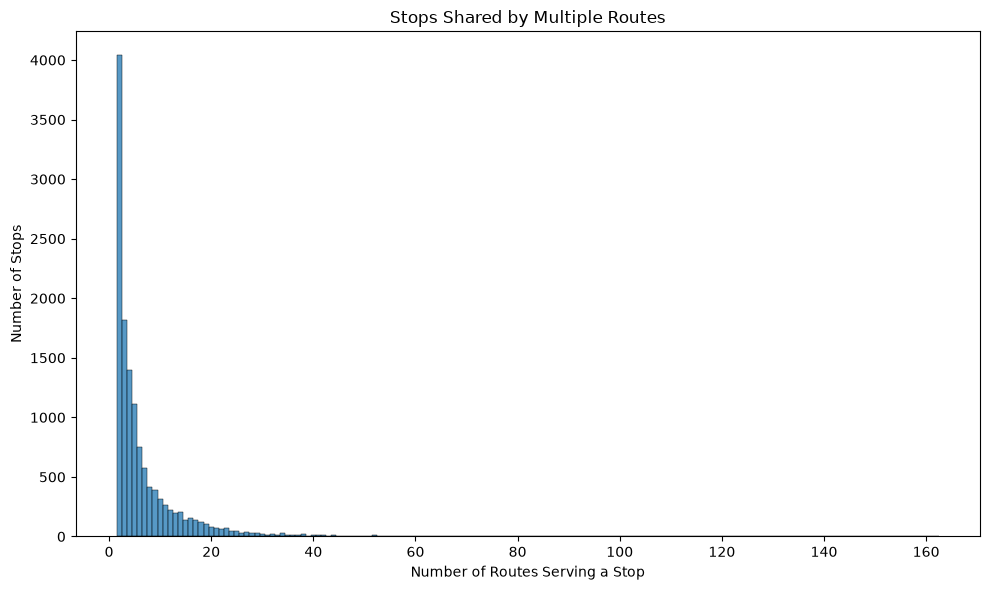

In [42]:
plt.figure(figsize=(10, 6))

sns.histplot(
    data=overlapping_stops,
    x="route_count",
    discrete=True
)

plt.title("Stops Shared by Multiple Routes")
plt.xlabel("Number of Routes Serving a Stop")
plt.ylabel("Number of Stops")
plt.tight_layout()
plt.show()


In [43]:

# Validate the stops with the highest route counts

print("Top 10 stops served by multiple routes:")
display(overlapping_stops.head(10))

# Check the highest-count stop in each city
print("\nMaximum routes serving a stop by city:")
display(
    overlapping_stops.groupby("city")["route_count"]
    .max()
    .sort_values(ascending=False)
)

# Check how many unique routes exist in each city
print("\nUnique routes by city:")
display(
    route_stops.groupby("city")["route_id"]
    .nunique()
    .sort_values(ascending=False)
)


Top 10 stops served by multiple routes:


,city,stop_id,route_count
2104,amhedabad,AMC_5978,162
5427,dharwad,8581,133
521,amhedabad,AMC_2107,116
20562,rajkot,71,115
249,amhedabad,AMC_1489,115
134,amhedabad,AMC_1212,102
5428,dharwad,8582,100
881,amhedabad,AMC_2863,99
70,amhedabad,AMC_1076,98
524,amhedabad,AMC_2110,97



Maximum routes serving a stop by city:


city
amhedabad    162
dharwad      133
rajkot       115
pune          66
mumbai        57
karnataka      8
vapi           6
Name: route_count, dtype: int64


Unique routes by city:


city
amhedabad    633
dharwad      630
mumbai       612
pune         309
rajkot       150
vapi          22
karnataka     14
Name: route_id, dtype: int64

Total routes analyzed: 2370
Potentially underutilized routes: 25


,city,route_id,unique_stop_count
1882,mumbai,931RING,1
689,dharwad,167,2
1851,mumbai,909LTD,2
778,dharwad,270,2
1858,mumbai,920LTD,2


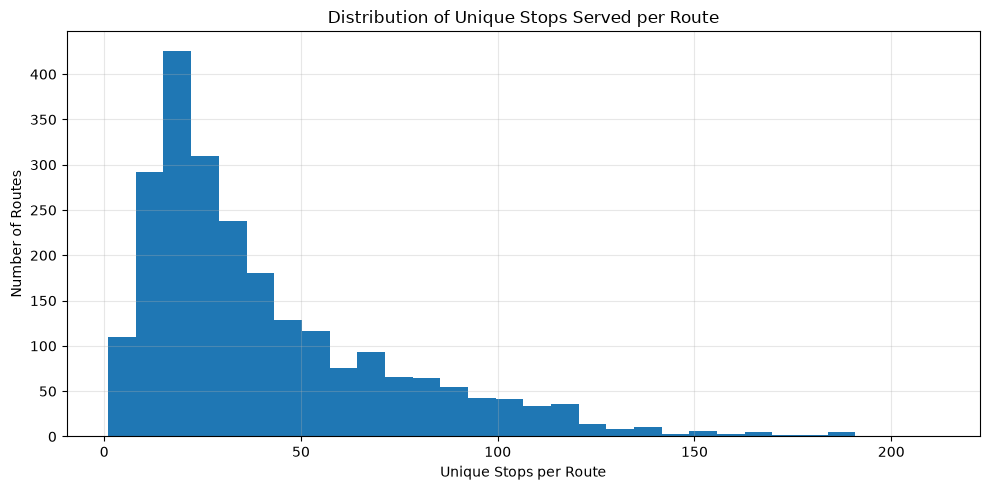

In [44]:
# Count unique stops served by each route
route_stop_counts = (
    route_stops.groupby(["city", "route_id"])["stop_id"]
    .nunique()
    .reset_index(name="unique_stop_count")
)

# Identify routes serving very few stops
underutilized_routes = (
    route_stop_counts[
        route_stop_counts["unique_stop_count"] <= 3
    ]
    .sort_values("unique_stop_count")
)

print("Total routes analyzed:", len(route_stop_counts))
print("Potentially underutilized routes:", len(underutilized_routes))

display(underutilized_routes.head())

# Visualize the distribution of stops per route
import matplotlib.pyplot as plt

plt.figure(figsize=(10, 5))
plt.hist(route_stop_counts["unique_stop_count"], bins=30)
plt.title("Distribution of Unique Stops Served per Route")
plt.xlabel("Unique Stops per Route")
plt.ylabel("Number of Routes")
plt.grid(alpha=0.3)
plt.tight_layout()
plt.show()


## Data Preprocessing

In [45]:
# Load datasets
routes = pd.read_csv("routes.csv")
frequency = pd.read_csv("route_trip_frequency.csv")
hourly = pd.read_csv("hourly_route_frequency.csv")

# Merge routes and trip frequency
df = pd.merge(
    routes,
    frequency,
    on=["city", "route_id"],
    how="left"
)

print(df.head())
print(df.shape)

        city route_id agency_id route_short_name  \
0  amhedabad    101sh      AMTS            101sh   
1  amhedabad    103-1      AMTS              103   
2  amhedabad    103-2      AMTS              103   
3  amhedabad    103-3      AMTS              103   
4  amhedabad      105      AMTS              105   

                                     route_long_name  route_type  \
0       P.D.P.U. Cross Road ⇆ Asarva Railway Station           3   
1                 Bhakti Circle ⇆ Gujarat University           3   
2                          Bhakti Circle ⇆ Sarangpur           3   
3                     Gujarat University ⇆ Sarangpur           3   
4  Naroda Industrial Township( MuthiyaGam ) ⇆ Lal...           3   

   trip_frequency  
0            10.0  
1            22.0  
2            14.0  
3             6.0  
4           216.0  
(2780, 7)


In [46]:
# Aggregate hourly frequency route-wise

hourly_features = hourly.groupby(
    ["city", "route_id"]
).agg(
    total_scheduled_trips=("scheduled_trips", "sum"),
    peak_hour_trips=("scheduled_trips", "max"),
    avg_hourly_trips=("scheduled_trips", "mean")
).reset_index()

# Merge hourly features with existing dataset

df = pd.merge(
    df,
    hourly_features,
    on=["city", "route_id"],
    how="left"
)


print(df.head())
print("Dataset shape:", df.shape)

        city route_id agency_id route_short_name  \
0  amhedabad    101sh      AMTS            101sh   
1  amhedabad    103-1      AMTS              103   
2  amhedabad    103-2      AMTS              103   
3  amhedabad    103-3      AMTS              103   
4  amhedabad      105      AMTS              105   

                                     route_long_name  route_type  \
0       P.D.P.U. Cross Road ⇆ Asarva Railway Station           3   
1                 Bhakti Circle ⇆ Gujarat University           3   
2                          Bhakti Circle ⇆ Sarangpur           3   
3                     Gujarat University ⇆ Sarangpur           3   
4  Naroda Industrial Township( MuthiyaGam ) ⇆ Lal...           3   

   trip_frequency  total_scheduled_trips  peak_hour_trips  avg_hourly_trips  
0            10.0                   22.0              2.0          1.571429  
1            22.0                   59.0              6.0          3.687500  
2            14.0                   27.0    

In [47]:
# Check data types
print("Column Data Types:")
print(df.dtypes)

# Separate numerical and categorical columns
numerical_cols = df.select_dtypes(
    include=["int64", "float64"]
).columns.tolist()

categorical_cols = df.select_dtypes(
    include=["object", "category"]
).columns.tolist()

print("\nNumerical Columns:")
print(numerical_cols)

print("\nCategorical Columns:")
print(categorical_cols)

# Check missing values
print("\nMissing Values:")
print(df.isnull().sum())

Column Data Types:
city                         str
route_id                     str
agency_id                    str
route_short_name             str
route_long_name              str
route_type                 int64
trip_frequency           float64
total_scheduled_trips    float64
peak_hour_trips          float64
avg_hourly_trips         float64
dtype: object

Numerical Columns:
['route_type', 'trip_frequency', 'total_scheduled_trips', 'peak_hour_trips', 'avg_hourly_trips']

Categorical Columns:
['city', 'route_id', 'agency_id', 'route_short_name', 'route_long_name']

Missing Values:
city                       0
route_id                   0
agency_id                  0
route_short_name           0
route_long_name            0
route_type                 0
trip_frequency           410
total_scheduled_trips    410
peak_hour_trips          410
avg_hourly_trips         410
dtype: int64


/tmp/ipykernel_5602/495497864.py:10: Pandas4Warning: For backward compatibility, 'str' dtypes are included by select_dtypes when 'object' dtype is specified. This behavior is deprecated and will be removed in a future version. Explicitly pass 'str' to `include` to select them, or to `exclude` to remove them and silence this warning.
See https://pandas.pydata.org/docs/dev/user_guide/migration.html#string-migration-select-dtypes for details on how to write code that works with pandas 2 and 3.
  categorical_cols = df.select_dtypes(


## handle missing valus

In [48]:
# Identify routes with missing frequency information

missing_routes = df[df["trip_frequency"].isnull()]

print("Routes with missing frequency:", len(missing_routes))

print(missing_routes[
    ["city", "route_id", "route_short_name"]
].head(10))

Routes with missing frequency: 410
           city                           route_id  \
626   amhedabad  Kalol To Pathikashram Via Sardhav   
627   amhedabad              Mansa To Pathikashram   
631   amhedabad  Pathikashram To Kalol Via Sardhav   
632   amhedabad              Pathikashram To Mansa   
634   amhedabad           Pathikashram To Pundhara   
637   amhedabad           Pundhara To Pathikashram   
1170    dharwad                                773   
1173    dharwad                                779   
1285  karnataka                               5571   
1286  karnataka                               5588   

                       route_short_name  
626   Kalol To Pathikashram Via Sardhav  
627               Mansa To Pathikashram  
631   Pathikashram To Kalol Via Sardhav  
632               Pathikashram To Mansa  
634            Pathikashram To Pundhara  
637            Pundhara To Pathikashram  
1170                              C16-U  
1173                              

In [49]:
# Check whether missing routes exist in frequency dataset

missing_keys = missing_routes[["city", "route_id"]].drop_duplicates()

frequency_keys = frequency[["city", "route_id"]].drop_duplicates()

check = missing_keys.merge(
    frequency_keys,
    on=["city", "route_id"],
    how="left",
    indicator=True
)

print(check["_merge"].value_counts())

print("\nSample unmatched routes:")
print(check[check["_merge"] == "left_only"].head(10))

_merge
left_only     410
right_only      0
both            0
Name: count, dtype: int64

Sample unmatched routes:
        city                           route_id     _merge
0  amhedabad  Kalol To Pathikashram Via Sardhav  left_only
1  amhedabad              Mansa To Pathikashram  left_only
2  amhedabad  Pathikashram To Kalol Via Sardhav  left_only
3  amhedabad              Pathikashram To Mansa  left_only
4  amhedabad           Pathikashram To Pundhara  left_only
5  amhedabad           Pundhara To Pathikashram  left_only
6    dharwad                                773  left_only
7    dharwad                                779  left_only
8  karnataka                               5571  left_only
9  karnataka                               5588  left_only


In [50]:
# Inspect frequency dataset

print("Frequency dataset shape:", frequency.shape)

print("\nFrequency columns:")
print(frequency.columns.tolist())

print("\nFrequency data types:")
print(frequency.dtypes)

print("\nFrequency sample:")
print(frequency.head(10))

print("\nUnique cities:")
print(frequency["city"].unique())


Frequency dataset shape: (2370, 3)

Frequency columns:
['city', 'route_id', 'trip_frequency']

Frequency data types:
city                str
route_id            str
trip_frequency    int64
dtype: object

Frequency sample:
        city  route_id  trip_frequency
0  amhedabad     101-C              96
1  amhedabad  101-C-PR               4
2  amhedabad  101-C-RS               3
3  amhedabad   101S-RM               6
4  amhedabad   101U-NR               6
5  amhedabad     101sh              10
6  amhedabad     102-1               6
7  amhedabad     102-2               2
8  amhedabad     102-3               8
9  amhedabad     103-1              22

Unique cities:
<ArrowStringArray>
['amhedabad', 'dharwad', 'karnataka', 'mumbai', 'pune', 'rajkot', 'vapi']
Length: 7, dtype: str


In [51]:
# Check missing route IDs in unmatched routes

print("Missing values in unmatched routes:")
print(missing_routes[
    ["city", "route_id", "route_short_name"]
].isnull().sum())

print("\nData types:")
print(missing_routes[
    ["city", "route_id", "route_short_name"]
].dtypes)

print("\nSample route IDs:")
print(missing_routes[
    ["city", "route_id", "route_short_name"]
].head(15).to_string(index=False))

Missing values in unmatched routes:
city                0
route_id            0
route_short_name    0
dtype: int64

Data types:
city                str
route_id            str
route_short_name    str
dtype: object

Sample route IDs:
     city                          route_id                  route_short_name
amhedabad Kalol To Pathikashram Via Sardhav Kalol To Pathikashram Via Sardhav
amhedabad             Mansa To Pathikashram             Mansa To Pathikashram
amhedabad Pathikashram To Kalol Via Sardhav Pathikashram To Kalol Via Sardhav
amhedabad             Pathikashram To Mansa             Pathikashram To Mansa
amhedabad          Pathikashram To Pundhara          Pathikashram To Pundhara
amhedabad          Pundhara To Pathikashram          Pundhara To Pathikashram
  dharwad                               773                             C16-U
  dharwad                               779                             C16-D
karnataka                              5571                      

In [52]:
# Count unmatched routes city-wise

city_missing = (
    missing_routes.groupby("city")
    .size()
    .sort_values(ascending=False)
)

print(city_missing)

city
mumbai       323
karnataka     79
amhedabad      6
dharwad        2
dtype: int64


In [53]:
# Handle missing frequency features

frequency_cols = [
    "trip_frequency",
    "total_scheduled_trips",
    "peak_hour_trips",
    "avg_hourly_trips"
]

# Create indicator before filling missing values
df["frequency_missing"] = df["trip_frequency"].isnull().astype(int)

# Fill missing values using city-wise median
for col in frequency_cols:

    df[col] = df.groupby("city")[col].transform(
        lambda x: x.fillna(x.median())
    )

    # Global median fallback
    df[col] = df[col].fillna(df[col].median())

print("Missing values after imputation:")
print(df[frequency_cols].isnull().sum())

print("\nDataset shape:", df.shape)

Missing values after imputation:
trip_frequency           0
total_scheduled_trips    0
peak_hour_trips          0
avg_hourly_trips         0
dtype: int64

Dataset shape: (2780, 11)


## Feature Engineerning

In [54]:
# Create route frequency category

def categorize_frequency(value):
    if value < 5:
        return "Low"
    elif value <= 15:
        return "Medium"
    else:
        return "High"

df["frequency_category"] = df["trip_frequency"].apply(
    categorize_frequency
)

print(df[["trip_frequency", "frequency_category"]].head(10))

print("\nCategory distribution:")
print(df["frequency_category"].value_counts())

   trip_frequency frequency_category
0            10.0             Medium
1            22.0               High
2            14.0             Medium
3             6.0             Medium
4           216.0               High
5             6.0             Medium
6             6.0             Medium
7             3.0                Low
8             1.0                Low
9             4.0                Low

Category distribution:
frequency_category
High      1644
Low        584
Medium     552
Name: count, dtype: int64


In [55]:
# Calculate peak-hour ratio

df["peak_hour_ratio"] = np.where(
    df["total_scheduled_trips"] > 0,
    df["peak_hour_trips"] / df["total_scheduled_trips"],
    0
)

print(df[[
    "route_id",
    "peak_hour_trips",
    "total_scheduled_trips",
    "peak_hour_ratio"
]].head(10))

print("\nPeak-hour ratio statistics:")
print(df["peak_hour_ratio"].describe())

  route_id  peak_hour_trips  total_scheduled_trips  peak_hour_ratio
0    101sh              2.0                   22.0         0.090909
1    103-1              6.0                   59.0         0.101695
2    103-2              4.0                   27.0         0.148148
3    103-3              3.0                   13.0         0.230769
4      105             31.0                  466.0         0.066524
5      107              2.0                   19.0         0.105263
6    109-1              3.0                   18.0         0.166667
7    109-2              2.0                    7.0         0.285714
8    109-3              1.0                    2.0         0.500000
9    109-4              2.0                    9.0         0.222222

Peak-hour ratio statistics:
count    2780.000000
mean        0.210972
std         0.235452
min         0.051095
25%         0.081761
50%         0.101852
75%         0.222222
max         1.000000
Name: peak_hour_ratio, dtype: float64


In [56]:
# Validate peak-hour ratio

print("Invalid ratios:")
print((df["peak_hour_ratio"] < 0).sum())

print("Ratios greater than 1:")
print((df["peak_hour_ratio"] > 1).sum())

print("Missing ratios:")
print(df["peak_hour_ratio"].isnull().sum())

print("Zero scheduled trips:")
print((df["total_scheduled_trips"] == 0).sum())

Invalid ratios:
0
Ratios greater than 1:
0
Missing ratios:
0
Zero scheduled trips:
0


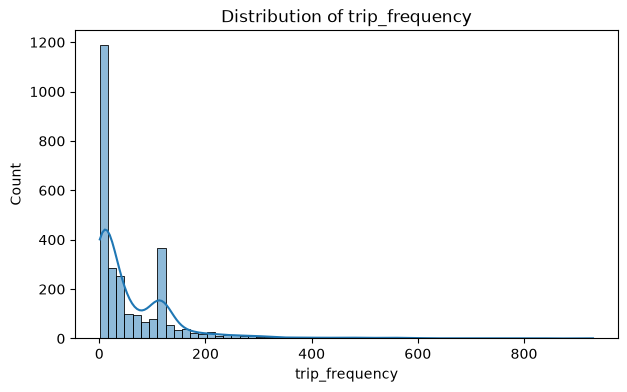

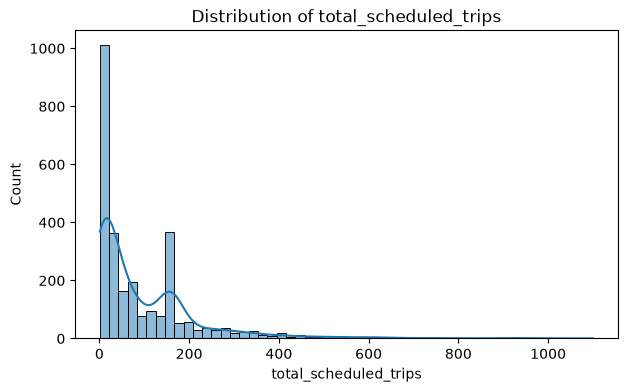

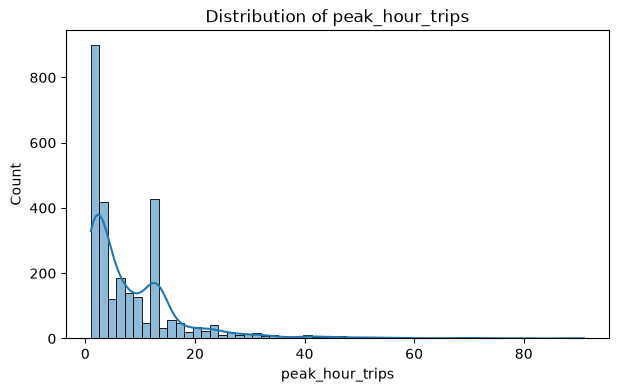

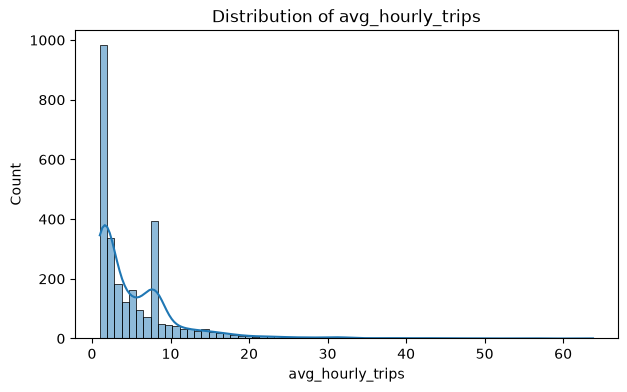

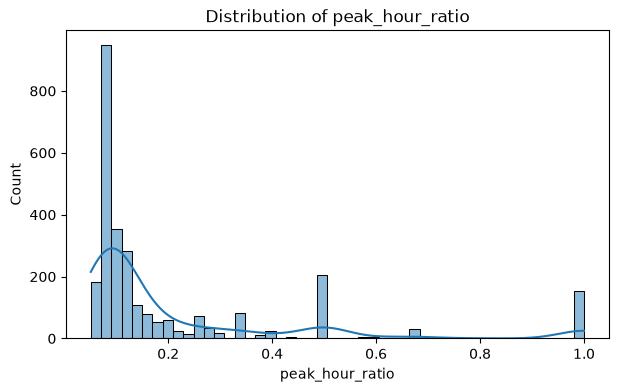

In [57]:
# How to numerical features are distrubted across the dataset
numerical_features = [
    "trip_frequency",
    "total_scheduled_trips",
    "peak_hour_trips",
    "avg_hourly_trips",
    "peak_hour_ratio"
]

for col in numerical_features:
    plt.figure(figsize=(7, 4))
    sns.histplot(df[col], kde=True)
    plt.title(f"Distribution of {col}")
    plt.xlabel(col)
    plt.ylabel("Count")
    plt.show()

In [58]:
# Select numerical features for Route Ranker

numerical_features = [
    "route_type",
    "trip_frequency",
    "total_scheduled_trips",
    "peak_hour_trips",
    "avg_hourly_trips",
    "peak_hour_ratio"
]

X = df[numerical_features].copy()

print("Selected Numerical Features:")
print(X.head())

print("\nFeature Dataset Shape:", X.shape)

Selected Numerical Features:
   route_type  trip_frequency  total_scheduled_trips  peak_hour_trips  \
0           3            10.0                   22.0              2.0   
1           3            22.0                   59.0              6.0   
2           3            14.0                   27.0              4.0   
3           3             6.0                   13.0              3.0   
4           3           216.0                  466.0             31.0   

   avg_hourly_trips  peak_hour_ratio  
0          1.571429         0.090909  
1          3.687500         0.101695  
2          1.928571         0.148148  
3          1.625000         0.230769  
4         24.526316         0.066524  

Feature Dataset Shape: (2780, 6)


In [59]:
# Store classification target separately

y = df["frequency_category"].copy()

print("Target Distribution:")
print(y.value_counts())

Target Distribution:
frequency_category
High      1644
Low        584
Medium     552
Name: count, dtype: int64


In [60]:
# Check feature ranges before scaling

print("Feature ranges before scaling:")
print(X.describe().loc[["min", "max"]])

Feature ranges before scaling:
     route_type  trip_frequency  total_scheduled_trips  peak_hour_trips  \
min         3.0             1.0                    1.0              1.0   
max         3.0           930.0                 1100.0             91.0   

     avg_hourly_trips  peak_hour_ratio  
min               1.0         0.051095  
max              63.8         1.000000  


In [61]:
# Identify constant features
constant_features = [
    col for col in X.columns
    if X[col].nunique() <= 1
]

print("Constant Features:", constant_features)

# Remove constant features
X = X.drop(columns=constant_features)

print("Updated Feature Dataset Shape:", X.shape)
print(X.head())

Constant Features: ['route_type']
Updated Feature Dataset Shape: (2780, 5)
   trip_frequency  total_scheduled_trips  peak_hour_trips  avg_hourly_trips  \
0            10.0                   22.0              2.0          1.571429   
1            22.0                   59.0              6.0          3.687500   
2            14.0                   27.0              4.0          1.928571   
3             6.0                   13.0              3.0          1.625000   
4           216.0                  466.0             31.0         24.526316   

   peak_hour_ratio  
0         0.090909  
1         0.101695  
2         0.148148  
3         0.230769  
4         0.066524  


In [62]:
# Calculate correlation matrix
correlation_matrix = X.corr()

print("Feature Correlation Matrix:")
print(correlation_matrix)

Feature Correlation Matrix:
                       trip_frequency  total_scheduled_trips  peak_hour_trips  \
trip_frequency               1.000000               0.948037         0.929805   
total_scheduled_trips        0.948037               1.000000         0.968411   
peak_hour_trips              0.929805               0.968411         1.000000   
avg_hourly_trips             0.947877               0.977679         0.974055   
peak_hour_ratio             -0.340792              -0.387783        -0.365520   

                       avg_hourly_trips  peak_hour_ratio  
trip_frequency                 0.947877        -0.340792  
total_scheduled_trips          0.977679        -0.387783  
peak_hour_trips                0.974055        -0.365520  
avg_hourly_trips               1.000000        -0.355937  
peak_hour_ratio               -0.355937         1.000000  


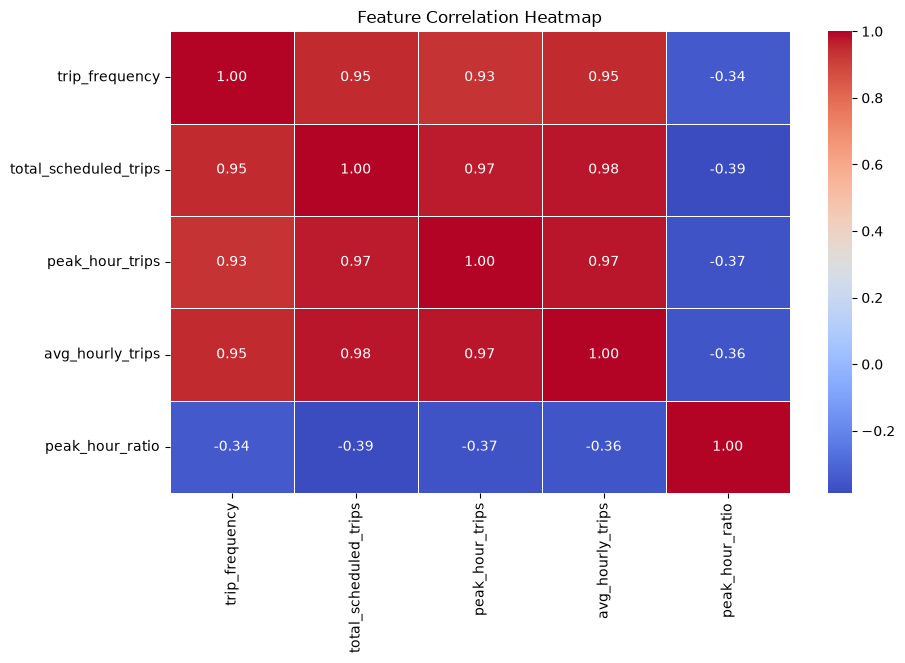

In [63]:

plt.figure(figsize=(10, 6))

sns.heatmap(
    correlation_matrix,
    annot=True,
    cmap="coolwarm",
    fmt=".2f",
    linewidths=0.5
)

plt.title("Feature Correlation Heatmap")
plt.show()

In [64]:
# Check target relationship with trip frequency
print("\nAverage trip frequency by category:")
print(df.groupby("frequency_category")["trip_frequency"].agg(
    ["min", "max", "mean", "count"]
))


Average trip frequency by category:
                     min    max        mean  count
frequency_category                                
High                16.0  930.0  107.288321   1644
Low                  1.0    4.0    1.979452    584
Medium               5.0   15.0    9.385870    552


In [65]:
# Remove target leakage feature
X = X.drop(columns=["trip_frequency"])

print("Updated Feature Dataset:")
print(X.head())

print("\nUpdated Shape:", X.shape)

Updated Feature Dataset:
   total_scheduled_trips  peak_hour_trips  avg_hourly_trips  peak_hour_ratio
0                   22.0              2.0          1.571429         0.090909
1                   59.0              6.0          3.687500         0.101695
2                   27.0              4.0          1.928571         0.148148
3                   13.0              3.0          1.625000         0.230769
4                  466.0             31.0         24.526316         0.066524

Updated Shape: (2780, 4)


In [66]:
# Remove highly correlated features

X = X.drop(columns=[
    "peak_hour_trips",
    "avg_hourly_trips"
])

print("Final Selected Features:")
print(X.head())

print("\nFinal Feature Dataset Shape:", X.shape)
print("\nSelected Columns:", X.columns.tolist())

Final Selected Features:
   total_scheduled_trips  peak_hour_ratio
0                   22.0         0.090909
1                   59.0         0.101695
2                   27.0         0.148148
3                   13.0         0.230769
4                  466.0         0.066524

Final Feature Dataset Shape: (2780, 2)

Selected Columns: ['total_scheduled_trips', 'peak_hour_ratio']


## train test split

In [67]:
from sklearn.model_selection import train_test_split
from sklearn.preprocessing import LabelEncoder

# Encode target labels
le = LabelEncoder()
y_encoded = le.fit_transform(y)

# Split dataset
X_train, X_test, y_train, y_test = train_test_split(
    X,
    y_encoded,
    test_size=0.2,
    random_state=42,
    stratify=y_encoded
)

# Check dataset shapes
print("Training Features:", X_train.shape)
print("Testing Features:", X_test.shape)

print("Training Target:", y_train.shape)
print("Testing Target:", y_test.shape)

Training Features: (2224, 2)
Testing Features: (556, 2)
Training Target: (2224,)
Testing Target: (556,)


## Feature Scaling (Standarization)

In [68]:
from sklearn.preprocessing import StandardScaler

# Initialize StandardScaler
scaler = StandardScaler()

# Fit on training data and transform
X_train_scaled = scaler.fit_transform(X_train)

# Transform testing data
X_test_scaled = scaler.transform(X_test)

# Check results
print("Training Data After Scaling:")
print(X_train_scaled[:5])

print("\nTesting Data After Scaling:")
print(X_test_scaled[:5])

print("\nTraining Shape:", X_train_scaled.shape)
print("Testing Shape:", X_test_scaled.shape)

Training Data After Scaling:
[[-0.56022406 -0.52413495]
 [ 1.66214524 -0.36028928]
 [ 0.67859666 -0.55469686]
 [-0.59025608 -0.44609573]
 [-0.67284413  1.23662502]]

Testing Data After Scaling:
[[-0.71789215  1.23662502]
 [-0.18482384 -0.1940718 ]
 [-0.57524007 -0.08284173]
 [ 0.49840456 -0.55690905]
 [-0.65782812  1.66291428]]

Training Shape: (2224, 2)
Testing Shape: (556, 2)


## Train Clustering Models (Unsupervised Learning)

In [69]:
from sklearn.cluster import KMeans, DBSCAN

# 1. Train KMeans Clustering
# Grouping routes into 4 distinct usage clusters
kmeans = KMeans(n_clusters=4, random_state=42)
cluster_labels_kmeans = kmeans.fit_predict(X_train_scaled)

# 2. Train DBSCAN Clustering
dbscan = DBSCAN(eps=0.5, min_samples=5)
cluster_labels_dbscan = dbscan.fit_predict(X_train_scaled)

# Check the distribution of clusters
print("KMeans Cluster Distribution :")
print(pd.Series(cluster_labels_kmeans).value_counts())

print("\nDBSCAN Cluster Distribution :")
print(pd.Series(cluster_labels_dbscan).value_counts())

KMeans Cluster Distribution :
0    1466
2     428
3     203
1     127
Name: count, dtype: int64

DBSCAN Cluster Distribution :
 0    2089
 1     123
 2      10
-1       2
Name: count, dtype: int64


## Train Classification Models (Supervised Learning)

In [70]:
from sklearn.ensemble import RandomForestClassifier
from xgboost import XGBClassifier
from sklearn.metrics import classification_report

# 1. Train Random Forest Classifier
rf_model = RandomForestClassifier(n_estimators=100, random_state=42)
rf_model.fit(X_train_scaled, y_train)
y_pred_rf = rf_model.predict(X_test_scaled)

# 2. Train XGBoost Classifier
xgb_model = XGBClassifier(random_state=42)
xgb_model.fit(X_train_scaled, y_train)
y_pred_xgb = xgb_model.predict(X_test_scaled)

# Print performance reports
print("Random Forest Classification Report :")
print(classification_report(y_test, y_pred_rf))

print("\nXGBoost Classification Report :")
print(classification_report(y_test, y_pred_xgb))

Random Forest Classification Report :
              precision    recall  f1-score   support

           0       0.97      0.96      0.96       329
           1       0.95      0.96      0.95       117
           2       0.84      0.85      0.85       110

    accuracy                           0.94       556
   macro avg       0.92      0.92      0.92       556
weighted avg       0.94      0.94      0.94       556


XGBoost Classification Report :
              precision    recall  f1-score   support

           0       0.97      0.97      0.97       329
           1       0.95      0.96      0.95       117
           2       0.85      0.85      0.85       110

    accuracy                           0.94       556
   macro avg       0.92      0.92      0.92       556
weighted avg       0.94      0.94      0.94       556



##  Classification Evaluation

In [71]:
from sklearn.metrics import silhouette_score, davies_bouldin_score

# KMeans Evaluation
print("KMeans Silhouette Score:",
      silhouette_score(X_train_scaled, cluster_labels_kmeans))

print("KMeans Davies-Bouldin Index:",
      davies_bouldin_score(X_train_scaled, cluster_labels_kmeans))

# DBSCAN Evaluation (exclude noise points)
mask = cluster_labels_dbscan != -1
db_labels = cluster_labels_dbscan[mask]
db_data = X_train_scaled[mask]

if len(set(db_labels)) >= 2:
    print("DBSCAN Silhouette Score:",
          silhouette_score(db_data, db_labels))

    print("DBSCAN Davies-Bouldin Index:",
          davies_bouldin_score(db_data, db_labels))
else:
    print("DBSCAN: Not enough clusters for evaluation")

KMeans Silhouette Score: 0.5732057546846943
KMeans Davies-Bouldin Index: 0.5283295302437792
DBSCAN Silhouette Score: 0.6623127406152368
DBSCAN Davies-Bouldin Index: 0.21855654814354794


## classifiction Evaluation

In [72]:
from sklearn.metrics import accuracy_score, confusion_matrix

print("Random Forest Accuracy:",
      accuracy_score(y_test, y_pred_rf))

print("XGBoost Accuracy:",
      accuracy_score(y_test, y_pred_xgb))

print("Random Forest Confusion Matrix:")
print(confusion_matrix(y_test, y_pred_rf))

print("XGBoost Confusion Matrix:")
print(confusion_matrix(y_test, y_pred_xgb))

Random Forest Accuracy: 0.9388489208633094
XGBoost Accuracy: 0.9406474820143885
Random Forest Confusion Matrix:
[[316   0  13]
 [  0 112   5]
 [ 10   6  94]]
XGBoost Confusion Matrix:
[[318   0  11]
 [  0 112   5]
 [ 11   6  93]]


##  route optimization Interface

In [73]:

# ADVANCED ROUTE OPTIMIZATION RECOMMENDATION ENGINE

#  Load the trained model

if "rf_model" not in globals():

    if os.path.exists("routeranker_rf_model.pkl"):
        rf_model = joblib.load("routeranker_rf_model.pkl")
    else:
        raise FileNotFoundError(
            "Trained Random Forest model file not found!"
        )

# Generate predictions

if "inference_df" not in globals():

    y_pred = rf_model.predict(X_test_scaled)

    inference_df = X_test.copy()

    inference_df["Predicted_Performance"] = y_pred

#  Prepare route features

route_features = X_test.copy()

# Reset index to maintain row alignment
route_features = route_features.reset_index(drop=True)
inference_df = inference_df.reset_index(drop=True)

#  Identify important columns

def find_column(keywords):

    for col in route_features.columns:

        if any(word in col.lower() for word in keywords):
            return col

    return None


frequency_col = find_column(["frequency", "trips"])

length_col = find_column(["length", "distance"])

usage_col = find_column([
    "passenger", "ridership", "usage", "demand"
])

print("Detected Route Features:")
print("Frequency:", frequency_col)
print("Length:", length_col)
print("Passenger Usage:", usage_col)


#  Generate recommendations

def advanced_recommendation(row, position):

    predicted_class = row["Predicted_Performance"]

    frequency = (
        route_features.iloc[position][frequency_col]
        if frequency_col else None
    )

    length = (
        route_features.iloc[position][length_col]
        if length_col else None
    )

    usage = (
        route_features.iloc[position][usage_col]
        if usage_col else None
    )

    # Overcrowded routes
    if predicted_class == 2:

        if (
            length_col is not None
            and pd.notna(length)
            and length > route_features[length_col].median()
        ):

            return "Increase Frequency / Evaluate Route Splitting"

        return "Increase Frequency / Add Extra Trips"

    # Moderate routes
    elif predicted_class == 1:

        return "Monitor Closely / Minor Schedule Adjustment"

    # Balanced routes
    else:

        if (
            usage_col is not None
            and pd.notna(usage)
            and usage <= route_features[usage_col].median()
        ):

            return "Review for Possible Route Merging"

        return "Maintain Current Schedule"

# Create optimization DataFrame

optimization_df = inference_df.copy()

optimization_df["Advanced_Recommendation"] = [
    advanced_recommendation(
        optimization_df.iloc[i], i
    )
    for i in range(len(optimization_df))
]

#  Display final results
print("\nAdvanced Route Optimization Recommendations")

display(optimization_df.head(15))

print("\nTotal Routes:", len(optimization_df))

print("\nRecommendation Distribution:")

display(
    optimization_df["Advanced_Recommendation"]
    .value_counts()
)


Detected Route Features:
Frequency: total_scheduled_trips
Length: None
Passenger Usage: None

Advanced Route Optimization Recommendations


,total_scheduled_trips,peak_hour_ratio,Predicted_Performance,Advanced_Recommendation
0,2.0,0.500000,1,Monitor Closely / Minor Schedule Adjustment
1,73.0,0.164384,0,Maintain Current Schedule
2,21.0,0.190476,2,Increase Frequency / Add Extra Trips
3,164.0,0.079268,0,Maintain Current Schedule
4,10.0,0.600000,2,Increase Frequency / Add Extra Trips
5,2.0,0.500000,1,Monitor Closely / Minor Schedule Adjustment
6,262.0,0.103053,0,Maintain Current Schedule
7,41.0,0.097561,0,Maintain Current Schedule
8,159.0,0.081761,0,Maintain Current Schedule
9,9.0,0.111111,2,Increase Frequency / Add Extra Trips



Total Routes: 556

Recommendation Distribution:


Advanced_Recommendation
Maintain Current Schedule                      326
Monitor Closely / Minor Schedule Adjustment    118
Increase Frequency / Add Extra Trips           112
Name: count, dtype: int64

## Before vs After Optimization

In [74]:
#  Compare Before and After Optimization

current_counts = inference_df["Predicted_Performance"].value_counts()

balanced = current_counts.get(0, 0)
moderate = current_counts.get(1, 0)
overcrowded = current_counts.get(2, 0)

# Simulation assumption: 20% of overcrowded routes improve
improved = round(overcrowded * 0.20)

comparison_df = pd.DataFrame({
    "Performance": ["Balanced", "Moderate", "Overcrowded"],
    "Before_Optimization": [
        balanced, moderate, overcrowded
    ],
    "After_Optimization": [
        balanced + improved,
        moderate,
        overcrowded - improved
    ]
})

print("Route Optimization Comparison")
display(comparison_df)


Route Optimization Comparison


,Performance,Before_Optimization,After_Optimization
0,Balanced,326,348
1,Moderate,118,118
2,Overcrowded,112,90


## Calculate optimization percentages

In [75]:

#  Calculate Optimization Impact Percentages

total_routes = comparison_df["Before_Optimization"].sum()

overcrowded_before = comparison_df.loc[
    comparison_df["Performance"] == "Overcrowded",
    "Before_Optimization"
].iloc[0]

overcrowded_after = comparison_df.loc[
    comparison_df["Performance"] == "Overcrowded",
    "After_Optimization"
].iloc[0]

before_percentage = (overcrowded_before / total_routes) * 100

after_percentage = (overcrowded_after / total_routes) * 100

reduction_percentage = (
    (overcrowded_before - overcrowded_after)
    / overcrowded_before
) * 100

print("Current Overcrowded Routes:",
      round(before_percentage, 2), "%")

print("Simulated Overcrowded Routes:",
      round(after_percentage, 2), "%")

print("Estimated Reduction:",
      round(reduction_percentage, 2), "%")


Current Overcrowded Routes: 20.14 %
Simulated Overcrowded Routes: 16.19 %
Estimated Reduction: 19.64 %


## Visualize optimization results

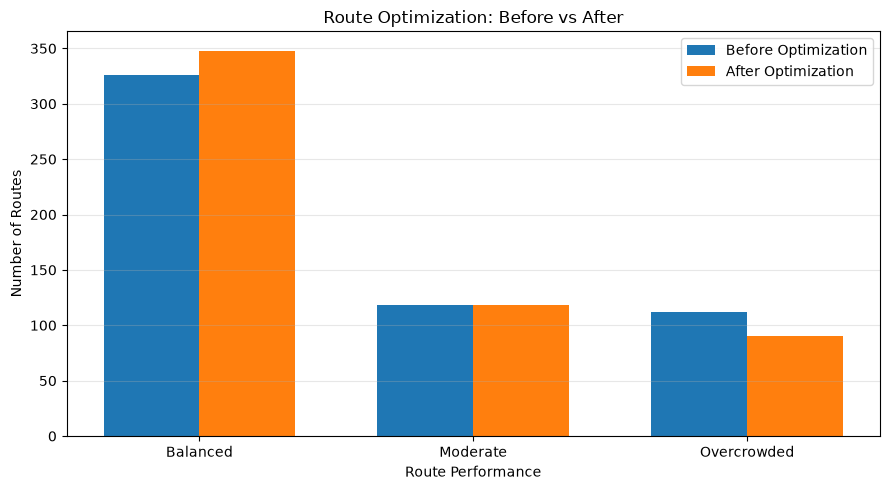

In [76]:
categories = comparison_df["Performance"]

before = comparison_df["Before_Optimization"]
after = comparison_df["After_Optimization"]

x = np.arange(len(categories))
width = 0.35

plt.figure(figsize=(9, 5))

plt.bar(x - width/2, before, width, label="Before Optimization")
plt.bar(x + width/2, after, width, label="After Optimization")

plt.xlabel("Route Performance")
plt.ylabel("Number of Routes")
plt.title("Route Optimization: Before vs After")

plt.xticks(x, categories)
plt.legend()
plt.grid(axis="y", alpha=0.3)

plt.tight_layout()
plt.show()


In [77]:
# Save Week 6 results

optimization_df.to_csv(
    "route_optimization_recommendations.csv",
    index=False
)

comparison_df.to_csv(
    "route_optimization_comparison.csv",
    index=False
)

print("Week 6 files saved successfully!")


Week 6 files saved successfully!
